# Reporte 1 Python: Visualización de una serie de tiempo

## 1. Identificación

**Nombre completo del estudiante:** Sofia Rojas  
**Código de la serie asignada:** F049.POB.PMT.INE9.01.M  
**Nombre o descripción de la variable:** Fuerza de trabajo nacional e inactivos  

**Explicación de la serie:**  
Esta serie de tiempo representa la población de 15 años y más en Chile, considerando tanto a las personas que forman parte de la fuerza de trabajo como a quienes se encuentran inactivas. La serie permite observar cómo evoluciona en el tiempo la población en edad de trabajar a nivel nacional y sirve como referencia para analizar cambios demográficos y del mercado laboral.

## 2. Importación de bibliotecas

In [16]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
%matplotlib inline

## 3. Carga del archivo

Se selecciona y carga el archivo CSV asignado desde el computador.

In [17]:
from google.colab import files
import io
import pandas as pd

uploaded = files.upload()
nombre_archivo = next(iter(uploaded))

df = pd.read_excel(io.BytesIO(uploaded[nombre_archivo]))

print(f'Archivo cargado correctamente: {nombre_archivo}')
display(df.head())

Saving Fuerza_de_trabajo_nacional_e_inactivos (1).xlsx to Fuerza_de_trabajo_nacional_e_inactivos (1).xlsx
Archivo cargado correctamente: Fuerza_de_trabajo_nacional_e_inactivos (1).xlsx


,"Fecha,Valor"
0,"2020-01-01,15543.054"
1,"2020-02-01,15570.352"
2,"2020-03-01,15597.572016866"
3,"2020-04-01,15624.834029417"
4,"2020-05-01,15652.082001223"


## 4. Exploración de los datos

In [18]:
# Primeras cinco observaciones
print("Primeras 5 observaciones:")
display(df.head())

# Nombre de las columnas
print("\nNombres de las columnas:")
print(df.columns.tolist())

# Cantidad de filas y columnas
print("\nDimensiones del DataFrame (filas, columnas):")
print(df.shape)

# Tipos de datos
print("\nTipos de datos:")
print(df.dtypes)

# Valores faltantes
print("\nValores faltantes por columna:")
print(df.isnull().sum())

Primeras 5 observaciones:


,"Fecha,Valor"
0,"2020-01-01,15543.054"
1,"2020-02-01,15570.352"
2,"2020-03-01,15597.572016866"
3,"2020-04-01,15624.834029417"
4,"2020-05-01,15652.082001223"



Nombres de las columnas:
['Fecha,Valor']

Dimensiones del DataFrame (filas, columnas):
(78, 1)

Tipos de datos:
Fecha,Valor    object
dtype: object

Valores faltantes por columna:
Fecha,Valor    0
dtype: int64


## 5. Preparación de la serie

Se identifica la columna de fecha, se convierte al formato correspondiente, se transforma la columna de valores a formato numérico y se ordenan las observaciones cronológicamente.

In [19]:
df.columns = df.columns.str.strip()
# Separar la fecha y el valor, que vienen juntos en el Excel.
if 'Fecha,Valor' in df.columns:
    df[['Fecha', 'Valor']] = df['Fecha,Valor'].str.split(',', n=1, expand=True)

df['Fecha'] = pd.to_datetime(df['Fecha'], errors='raise')
df['Valor'] = pd.to_numeric(df['Valor'], errors='raise')
df_serie = df[['Fecha', 'Valor']].sort_values('Fecha').reset_index(drop=True)

# Verificar calidad y frecuencia de los datos.
assert not df_serie.isna().any().any(), 'Existen datos faltantes'
assert not df_serie['Fecha'].duplicated().any(), 'Existen fechas repetidas'
assert df_serie['Fecha'].tolist() == list(pd.date_range(df_serie['Fecha'].min(), df_serie['Fecha'].max(), freq='MS')), 'Faltan meses'
display(df_serie.head())
print('Observaciones:', len(df_serie))
print('Rango:', df_serie['Fecha'].min(), 'a', df_serie['Fecha'].max())
print('Tipos:', df_serie.dtypes)
print('Valores faltantes:', df_serie.isna().sum())

,Fecha,Valor
0,2020-01-01,15543.054000
1,2020-02-01,15570.352000
2,2020-03-01,15597.572017
3,2020-04-01,15624.834029
4,2020-05-01,15652.082001


Observaciones: 78
Rango: 2020-01-01 00:00:00 a 2026-06-01 00:00:00
Tipos: Fecha    datetime64[ns]
Valor           float64
dtype: object
Valores faltantes: Fecha    0
Valor    0
dtype: int64


## 6. Elaboración del gráfico

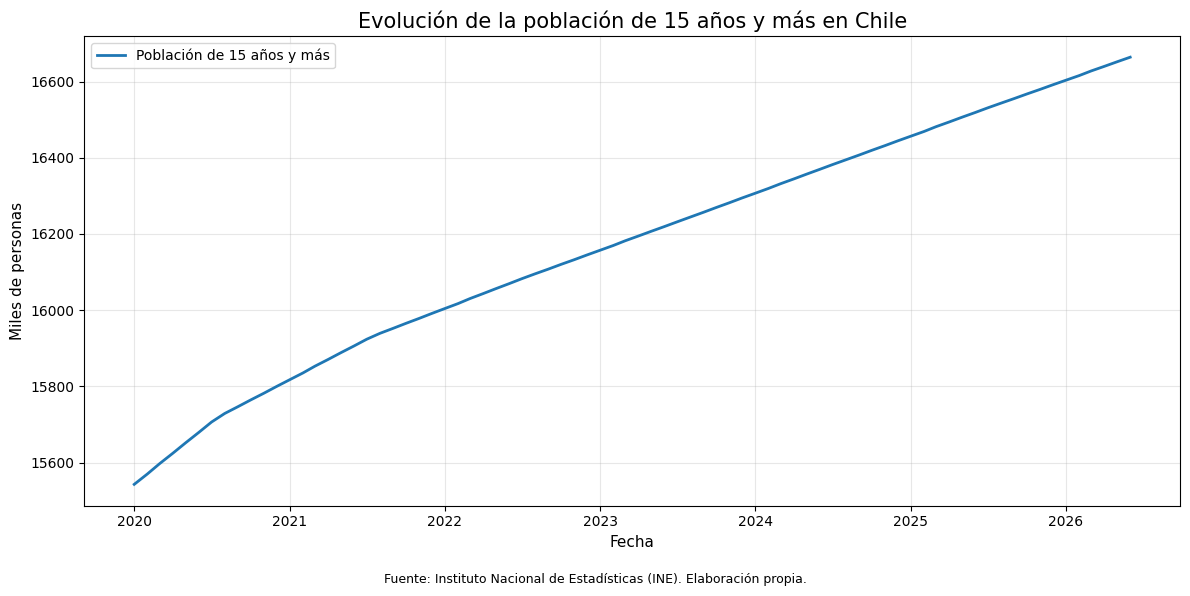

In [20]:
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(
    df_serie['Fecha'],
    df_serie['Valor'],
    label='Población de 15 años y más',
    linewidth=2
)

ax.set_title('Evolución de la población de 15 años y más en Chile', fontsize=15)
ax.set_xlabel('Fecha', fontsize=11)
ax.set_ylabel('Miles de personas', fontsize=11)
ax.legend()
ax.grid(alpha=0.3)

# Fuente de los datos
fig.text(
    0.5, 0.02,
    'Fuente: Instituto Nacional de Estadísticas (INE). Elaboración propia.',
    ha='center',
    fontsize=9
)

fig.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()


## 7. Interpretación

El gráfico muestra una **tendencia general creciente** de la población de 15 años y más en Chile entre 2020 y 2026. Al comienzo del período, la serie se ubica en torno a **15,5 millones de personas**, mientras que hacia el final supera los **16,5 millones**, lo que evidencia un aumento sostenido en el tiempo. No se observan disminuciones bruscas ni períodos prolongados de caída; por el contrario, el crecimiento es relativamente continuo. Los valores más bajos se concentran al inicio de la serie y los más altos aparecen en los meses finales. Tampoco se aprecia una estacionalidad marcada ni fluctuaciones mensuales de gran magnitud. En términos generales, el comportamiento de la serie es estable y ascendente, lo que sugiere un crecimiento gradual de la población en edad de trabajar durante el período analizado.

## 8. Descomposición de la serie temporal

Vamos a descomponer la serie para identificar formalmente la tendencia, la estacionalidad y los residuos. Esto nos ayudará a entender mejor la estructura subyacente de los datos.

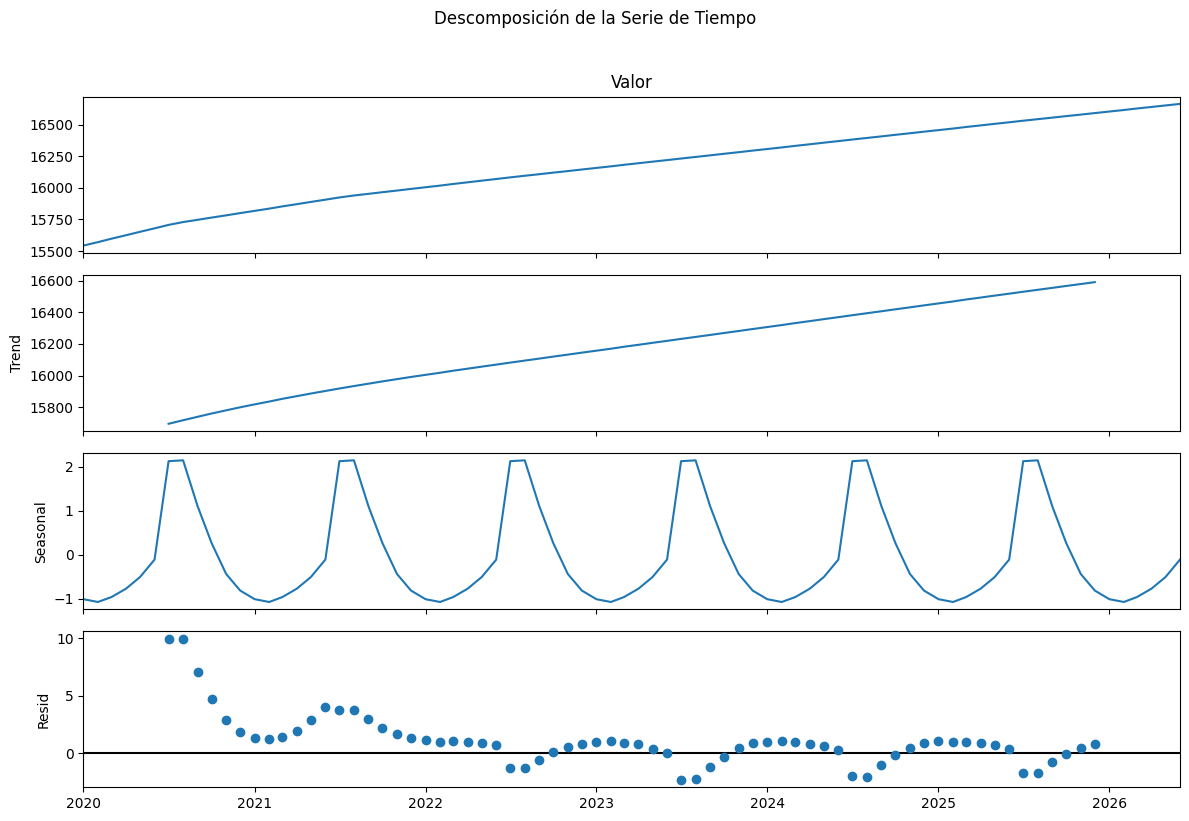

In [21]:
import statsmodels.api as sm

# Asegurarse de que la columna de fecha sea el índice para la descomposición
df_serie_indexed = df_serie.set_index('Fecha')

# Descomposición aditiva de la serie de tiempo
# 'model=add' se usa cuando la magnitud de las fluctuaciones estacionales no depende del nivel de la serie
# 'period' debe ser la frecuencia de los datos. En este caso, son datos mensuales, por lo que el período es 12.
decomposition = sm.tsa.seasonal_decompose(df_serie_indexed['Valor'], model='additive', period=12)

# Graficar los componentes de la descomposición
fig = decomposition.plot()
fig.set_size_inches(12, 8)
fig.suptitle('Descomposición de la Serie de Tiempo', y=1.02)
plt.tight_layout()
plt.show()

### Análisis de los componentes:

*   **Tendencia (Trend):** Muestra la dirección a largo plazo de la serie, confirmando la tendencia creciente identificada previamente.
*   **Estacionalidad (Seasonal):** Refleja patrones que se repiten en intervalos regulares. En este caso, la visualización de este componente puede ayudar a identificar si existe alguna estacionalidad mensual, aunque previamente se indicó que no era 'marcada'.
*   **Residuos (Residual):** Representan el ruido o las variaciones irregulares en la serie después de eliminar la tendencia y la estacionalidad. Idealmente, los residuos deberían ser aleatorios.

## 9. Prueba de Estacionariedad (ADF Test)

La estacionariedad es una suposición importante para muchos modelos de series de tiempo. Una serie de tiempo estacionaria tiene propiedades estadísticas (como la media y la varianza) que no cambian con el tiempo. Utilizaremos la prueba de Dickey-Fuller Aumentada (ADF) para determinar si la serie es estacionaria.

In [22]:
from statsmodels.tsa.stattools import adfuller
# Dada la tendencia visible, se reporta también una prueba con tendencia determinista.
for modelo, etiqueta in [('c', 'Constante'), ('ct', 'Constante y tendencia')]:
    resultado = adfuller(df_serie_indexed['Valor'], regression=modelo)
    print(etiqueta)
    print(f'Estadístico ADF: {resultado[0]:.4f}')
    print(f'P-valor: {resultado[1]:.4f}')
    print('Valores críticos:', resultado[4])
    print('Se rechaza H0' if resultado[1] <= 0.05 else 'No se rechaza H0', '\n')

Constante
Estadístico ADF: 0.9856
P-valor: 0.9941
Valores críticos: {'1%': np.float64(-3.5352168748293127), '5%': np.float64(-2.9071540828402367), '10%': np.float64(-2.5911025443786984)}
No se rechaza H0 

Constante y tendencia
Estadístico ADF: -4.7872
P-valor: 0.0005
Valores críticos: {'1%': np.float64(-4.102930985196315), '5%': np.float64(-3.4792434170910203), '10%': np.float64(-3.167204658151766)}
Se rechaza H0 



/tmp/ipykernel_1112/2307751775.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(df_serie_indexed['Valor'], regression=modelo)
/tmp/ipykernel_1112/2307751775.py:4: FutureWarning: adfuller currently returns a plain tuple whose length depends on the store and autolag arguments. In release 0.16 or after July 2027, whichever is later, the default behavior will switch to always returning an ADFullerResult. Set result_object=True to switch now, or result_object=False to keep the current behavior and silence this warning.
  resultado = adfuller(df_serie_indexed['Valor'], regression=modelo)


### Interpretación de la prueba ADF:

*   **Hipótesis Nula (H0):** La serie temporal tiene una raíz unitaria (es decir, no es estacionaria).
*   **Hipótesis Alternativa (H1):** La serie temporal no tiene una raíz unitaria (es decir, es estacionaria).

Si el p-valor es menor o igual al nivel de significancia (comúnmente 0.05), rechazamos la hipótesis nula y concluimos que la serie es estacionaria. Si el p-valor es mayor que 0.05, no rechazamos la hipótesis nula, lo que sugiere que la serie no es estacionaria.